<a href="https://colab.research.google.com/github/ThePretelR/cassava-disease-model-comparison/blob/main/notebooks/02_entrenamiento_E0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experimento E0 — CNN entrenada desde cero

## 1. Configuración del entorno

Este experimento establece una línea base para la clasificación
de cinco enfermedades y estados de hojas de yuca.

Se utilizarán las particiones depuradas del dataset Cassava,
con 9.361 imágenes en total.

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import random
import time

# Semilla para reproducibilidad
SEED = 42

tf.keras.utils.set_random_seed(SEED)

# Configuración experimental
IMG_SIZE = (224, 224)
BATCH_SIZE = 8
EPOCHS = 15
NUM_CLASSES = 5

CLASS_NAMES = [
    "cbb",
    "cbsd",
    "cgm",
    "cmd",
    "healthy"
]

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))
print("Tamaño de imagen:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Épocas máximas:", EPOCHS)
print("Semilla:", SEED)

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Tamaño de imagen: (224, 224)
Batch size: 8
Épocas máximas: 15
Semilla: 42


## 2. Carga del dataset y reconstrucción de particiones

Se carga Cassava desde TensorFlow Datasets y se utiliza el
manifiesto final del EDA para seleccionar las 9.361 imágenes
conservadas después de la depuración.

In [ ]:
%pip -q install tensorflow-datasets importlib_resources

In [ ]:
import pandas as pd

URL_MANIFIESTO = (
    "https://raw.githubusercontent.com/"
    "ThePretelR/cassava-disease-model-comparison/"
    "main/results/eda/manifiesto_final_conservados.csv"
)

df_manifest = pd.read_csv(URL_MANIFIESTO)

print("Registros del manifiesto:", len(df_manifest))
print("\nDistribución por partición:")
print(df_manifest["particion"].value_counts())

assert len(df_manifest) == 9361
assert not df_manifest.duplicated(
    ["particion", "indice"]
).any()

print("\nManifiesto cargado correctamente.")

Registros del manifiesto: 9361

Distribución por partición:
particion
train         5610
validation    1877
test          1874
Name: count, dtype: int64

Manifiesto cargado correctamente.


In [ ]:
import tensorflow_datasets as tfds

(ds_train, ds_val, ds_test), info = tfds.load(
    "cassava:0.1.0",
    split=["train", "validation", "test"],
    as_supervised=True,
    with_info=True,
    shuffle_files=False
)

print("Dataset:", info.name)
print("Versión:", info.version)

print("Train original:", info.splits["train"].num_examples)
print("Validation original:", info.splits["validation"].num_examples)
print("Test original:", info.splits["test"].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.
Dataset: cassava
Versión: 0.1.0
Train original: 5656
Validation original: 1889
Test original: 1885


In [ ]:
def aplicar_manifiesto(dataset, particion):
    indices = set(
        df_manifest.loc[
            df_manifest["particion"] == particion,
            "indice"
        ].astype(int)
    )

    total = int(dataset.cardinality().numpy())

    mascara = tf.constant(
        [i in indices for i in range(total)],
        dtype=tf.bool
    )

    return (
        dataset.enumerate()
        .filter(lambda i, dato: tf.gather(mascara, i))
        .map(lambda i, dato: dato)
    )


ds_train_final = aplicar_manifiesto(ds_train, "train")
ds_val_final = aplicar_manifiesto(ds_val, "validation")
ds_test_final = aplicar_manifiesto(ds_test, "test")

n_train = sum(1 for _ in ds_train_final)
n_val = sum(1 for _ in ds_val_final)
n_test = sum(1 for _ in ds_test_final)

print("Train:", n_train)
print("Validation:", n_val)
print("Test:", n_test)
print("Total:", n_train + n_val + n_test)

assert (n_train, n_val, n_test) == (5610, 1877, 1874)

print("\nParticiones reconstruidas correctamente.")

Train: 5610
Validation: 1877
Test: 1874
Total: 9361

Particiones reconstruidas correctamente.


## 3. Verificación de integridad de las particiones

Se comprueba que los registros reconstruidos coincidan con
el manifiesto del EDA mediante hashes SHA-256.

In [ ]:
import hashlib

def obtener_hash(imagen):
    img = imagen.numpy()

    h = hashlib.sha256()
    h.update(str(img.shape).encode("utf-8"))
    h.update(img.tobytes())

    return h.hexdigest()


datasets_originales = {
    "train": ds_train,
    "validation": ds_val,
    "test": ds_test
}

for particion, dataset in datasets_originales.items():

    # Hash esperado por índice original
    esperados = dict(
        zip(
            df_manifest.loc[
                df_manifest["particion"] == particion,
                "indice"
            ].astype(int),
            df_manifest.loc[
                df_manifest["particion"] == particion,
                "hash"
            ]
        )
    )

    verificados = 0
    errores = []

    for indice, (imagen, etiqueta) in enumerate(dataset):

        if indice not in esperados:
            continue

        hash_actual = obtener_hash(imagen)

        if hash_actual != esperados[indice]:
            errores.append(indice)

        verificados += 1

    print(
        f"{particion}: {verificados} verificadas, "
        f"{len(errores)} discrepancias"
    )

    assert verificados == len(esperados), (
        f"Faltan registros en {particion}"
    )

    assert len(errores) == 0, (
        f"Hashes diferentes en {particion}: {errores[:10]}"
    )

print("\nIntegridad de las particiones verificada correctamente.")

train: 5610 verificadas, 0 discrepancias
validation: 1877 verificadas, 0 discrepancias
test: 1874 verificadas, 0 discrepancias

Integridad de las particiones verificada correctamente.


## 4. Preprocesamiento de imágenes

Las imágenes se redimensionan a 224 × 224 píxeles y se
normalizan al intervalo [0, 1].

Se aplica mezcla aleatoria únicamente al conjunto de entrenamiento.
Las particiones de validación y prueba mantienen un orden determinista.

Se utiliza un tamaño de lote de 32 imágenes.

In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 8

def preprocesar_imagen(imagen, etiqueta):
    imagen = tf.image.resize(
        imagen,
        IMG_SIZE,
        method="bilinear"
    )

    imagen = tf.cast(imagen, tf.float32) / 255.0
    etiqueta = tf.cast(etiqueta, tf.int32)

    return imagen, etiqueta

print("Función de preprocesamiento definida correctamente.")

Función de preprocesamiento definida correctamente.


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    ds_train_final
    .shuffle(
        buffer_size=512,
        seed=SEED,
        reshuffle_each_iteration=True
    )
    .map(
        preprocesar_imagen,
        num_parallel_calls=2
    )
    .batch(BATCH_SIZE)
    .prefetch(1)
)

val_ds = (
    ds_val_final
    .map(
        preprocesar_imagen,
        num_parallel_calls=2
    )
    .batch(BATCH_SIZE)
    .prefetch(1)
)

test_ds = (
    ds_test_final
    .map(
        preprocesar_imagen,
        num_parallel_calls=2
    )
    .batch(BATCH_SIZE)
    .prefetch(1)
)

print("Datasets preparados correctamente.")

Datasets preparados correctamente.


In [ ]:
train_ds = (
    ds_train_final
    .map(preprocesar_imagen, num_parallel_calls=AUTOTUNE)
    .shuffle(
        buffer_size=5610,
        seed=SEED,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    ds_val_final
    .map(preprocesar_imagen, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    ds_test_final
    .map(preprocesar_imagen, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Datasets preparados correctamente.")

Datasets preparados correctamente.


In [ ]:
imagenes, etiquetas = next(iter(train_ds))

print("Forma de las imágenes:", imagenes.shape)
print("Forma de las etiquetas:", etiquetas.shape)

print("Valor mínimo:", float(tf.reduce_min(imagenes)))
print("Valor máximo:", float(tf.reduce_max(imagenes)))

print("Tipo de imágenes:", imagenes.dtype)
print("Tipo de etiquetas:", etiquetas.dtype)

print("Etiquetas presentes:", np.unique(etiquetas.numpy()))

assert imagenes.shape[1:] == (224, 224, 3)
assert imagenes.dtype == tf.float32
assert float(tf.reduce_min(imagenes)) >= 0.0
assert float(tf.reduce_max(imagenes)) <= 1.0
assert np.all(
    (etiquetas.numpy() >= 0) &
    (etiquetas.numpy() < NUM_CLASSES)
)

print("\nPreprocesamiento verificado correctamente.")

Forma de las imágenes: (8, 224, 224, 3)
Forma de las etiquetas: (8,)
Valor mínimo: 0.0
Valor máximo: 1.0
Tipo de imágenes: <dtype: 'float32'>
Tipo de etiquetas: <dtype: 'int32'>
Etiquetas presentes: [0 1 3 4]

Preprocesamiento verificado correctamente.


## 5. Arquitectura de la CNN base (E0)

Se implementa una red neuronal convolucional pequeña,
entrenada desde cero y sin utilizar pesos preentrenados.

La arquitectura contiene tres bloques convolucionales,
seguidos de una capa densa y una salida Softmax
para clasificar las cinco clases del dataset Cassava.

In [ ]:
from tensorflow.keras import layers, models

modelo_e0 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Bloque convolucional 1
    layers.Conv2D(32, (3, 3), activation="relu",
                  padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Bloque convolucional 2
    layers.Conv2D(64, (3, 3), activation="relu",
                  padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Bloque convolucional 3
    layers.Conv2D(128, (3, 3), activation="relu",
                  padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Clasificación
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="CNN_E0")

modelo_e0.summary()

Model: "CNN_E0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
modelo_e0.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=[
        "accuracy"
    ]
)

print("Modelo E0 compilado correctamente.")
print("Parámetros totales:", modelo_e0.count_params())

Modelo E0 compilado correctamente.
Parámetros totales: 110405


In [ ]:
import os

os.makedirs("results/e0", exist_ok=True)

callbacks_e0 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath="results/e0/mejor_modelo_e0.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.CSVLogger(
        "results/e0/historial_entrenamiento.csv"
    )
]

print("Callbacks configurados correctamente.")

Callbacks configurados correctamente.


## 6. Entrenamiento del modelo E0

Se entrena una CNN desde cero durante un máximo de 15 épocas,
utilizando Adam con una tasa de aprendizaje de 0.001.

Se emplean EarlyStopping y ModelCheckpoint para controlar
el sobreajuste y conservar el mejor modelo según val_loss.

Se registra el tiempo total de entrenamiento.

In [ ]:
import psutil

class MonitorMemoria(tf.keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):
        memoria = psutil.virtual_memory()

        print(
            f"\nÉpoca {epoch + 1}: "
            f"RAM usada = {memoria.percent}% | "
            f"RAM disponible = "
            f"{memoria.available / 1024**3:.2f} GB"
        )

callbacks_e0.append(MonitorMemoria())

In [ ]:
import time
import math

PASOS_ENTRENAMIENTO = math.ceil(n_train / BATCH_SIZE)
PASOS_VALIDACION = math.ceil(n_val / BATCH_SIZE)

print("Pasos de entrenamiento:", PASOS_ENTRENAMIENTO)
print("Pasos de validación:", PASOS_VALIDACION)

inicio_e0 = time.perf_counter()

historial_e0 = modelo_e0.fit(
    train_ds.repeat(),
    validation_data=val_ds.repeat(),
    steps_per_epoch=PASOS_ENTRENAMIENTO,
    validation_steps=PASOS_VALIDACION,
    epochs=EPOCHS,
    callbacks=callbacks_e0,
    verbose=1
)

tiempo_entrenamiento_e0 = time.perf_counter() - inicio_e0

print("\nEntrenamiento E0 finalizado.")
print(f"Tiempo total: {tiempo_entrenamiento_e0:.2f} segundos")
print(f"Épocas ejecutadas: {len(historial_e0.history['loss'])}")

Pasos de entrenamiento: 702
Pasos de validación: 235
Epoch 1/15
702/702 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4684 - loss: 1.3734
Época 1: RAM usada = 53.3% | RAM disponible = 5.91 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 71s 60ms/step - accuracy: 0.4704 - loss: 1.3496 - val_accuracy: 0.4715 - val_loss: 1.3161
Epoch 2/15
701/702 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4739 - loss: 1.3144
Época 2: RAM usada = 54.4% | RAM disponible = 5.77 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 22s 32ms/step - accuracy: 0.4996 - loss: 1.2833 - val_accuracy: 0.5802 - val_loss: 1.1406
Epoch 3/15
700/702 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5490 - loss: 1.2249
Época 3: RAM usada = 55.7% | RAM disponible = 5.61 GB
702/702 ━━━━━━━━━━━━━━━━━━━━ 33s 32ms/step - accuracy: 0.5709 - loss: 1.1798 - val_accuracy: 0.6212 - val_loss: 1.0865
Epoch 4/15
700/702 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5888 - loss: 1.1434
Época 4: RAM usada = 56.1% | RAM disponible = 5.56 GB
702/702 ━━━━━━━━━━━━━━━━━━

## 7. Evaluación del modelo E0 en validación

Se evalúa el modelo CNN entrenado desde cero utilizando el
conjunto de validación. Se calculan accuracy, Macro-F1,
precision, recall y F1-score por clase.

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Etiquetas reales de validación
y_true = np.concatenate([
    etiquetas.numpy()
    for _, etiquetas in val_ds
])

# Predicciones del modelo
probabilidades = modelo_e0.predict(
    val_ds,
    verbose=1
)

y_pred = np.argmax(probabilidades, axis=1)

# Métricas generales
accuracy_e0 = accuracy_score(y_true, y_pred)
macro_f1_e0 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(f"Accuracy E0: {accuracy_e0:.4f}")
print(f"Macro-F1 E0: {macro_f1_e0:.4f}")

print("\nReporte por clase:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


Accuracy E0: 0.6787
Macro-F1 E0: 0.4699

Reporte por clase:
              precision    recall  f1-score   support

         cbb       0.64      0.11      0.18       151
        cbsd       0.62      0.80      0.70       479
         cgm       0.46      0.12      0.19       257
         cmd       0.76      0.90      0.82       885
     healthy       0.43      0.50      0.46       105

    accuracy                           0.68      1877
   macro avg       0.58      0.48      0.47      1877
weighted avg       0.65      0.68      0.63      1877



In [ ]:
import os
from sklearn.metrics import classification_report, confusion_matrix

os.makedirs("results/e0", exist_ok=True)

# Reporte por clase
reporte_e0 = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(reporte_e0).transpose().to_csv(
    "results/e0/reporte_clasificacion.csv",
    index=True
)

# Matriz de confusión
matriz_e0 = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

pd.DataFrame(
    matriz_e0,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv("results/e0/matriz_confusion.csv")

# Resumen general
pd.DataFrame([{
    "modelo": "E0_CNN",
    "accuracy": accuracy_e0,
    "macro_f1": macro_f1_e0,
    "tiempo_entrenamiento_segundos": tiempo_entrenamiento_e0,
    "epocas_ejecutadas": len(historial_e0.history["loss"])
}]).to_csv("results/e0/resumen_metricas.csv", index=False)

print("Archivos guardados correctamente:")
print(os.listdir("results/e0"))

Archivos guardados correctamente:
['historial_entrenamiento.csv', 'mejor_modelo_e0.keras', 'resumen_metricas.csv', 'reporte_clasificacion.csv', 'matriz_confusion.csv']


## 8. Visualización de resultados E0

Se presenta la matriz de confusión y las curvas de aprendizaje
del modelo CNN E0 para analizar su rendimiento durante el
entrenamiento y la validación.

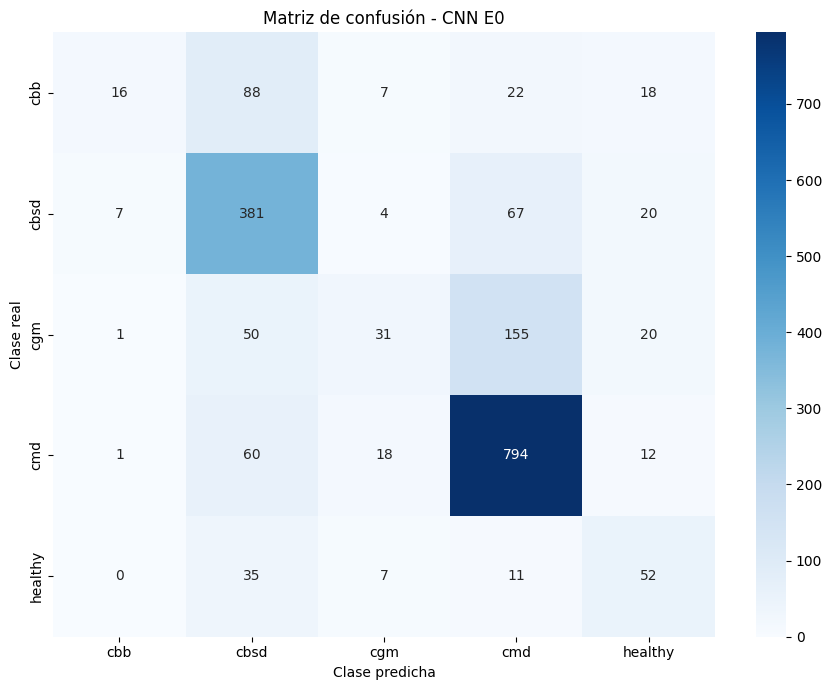

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calcular matriz de confusión
matriz_e0 = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

# Crear gráfica
plt.figure(figsize=(9, 7))

sns.heatmap(
    matriz_e0,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Matriz de confusión - CNN E0")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()

# Guardar imagen
plt.savefig(
    "results/e0/matriz_confusion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

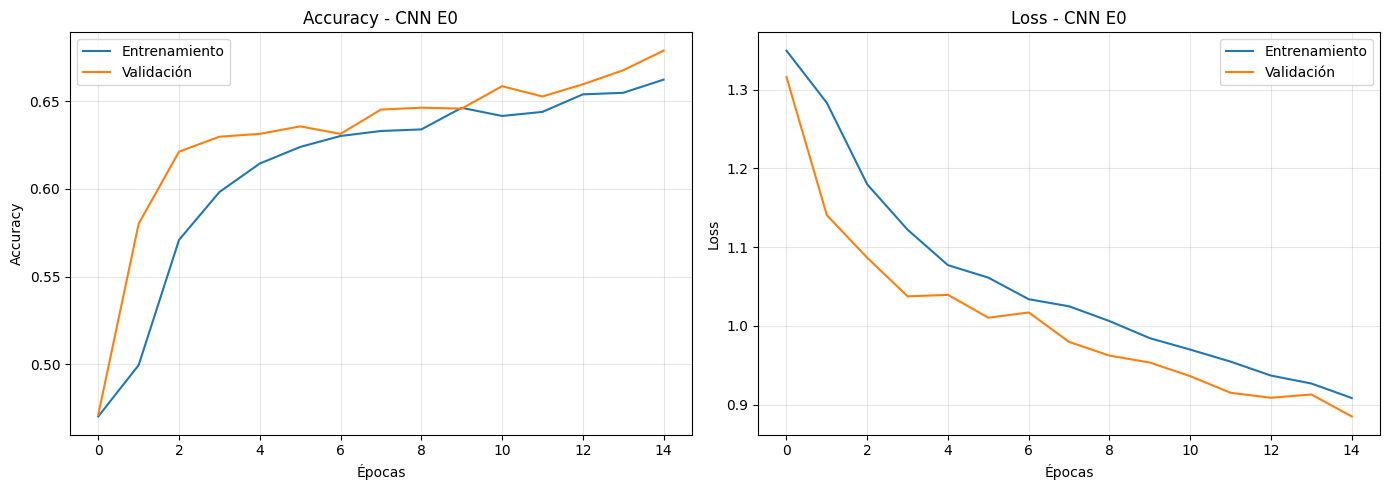

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(
    historial_e0.history["accuracy"],
    label="Entrenamiento"
)
axes[0].plot(
    historial_e0.history["val_accuracy"],
    label="Validación"
)

axes[0].set_title("Accuracy - CNN E0")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(
    historial_e0.history["loss"],
    label="Entrenamiento"
)
axes[1].plot(
    historial_e0.history["val_loss"],
    label="Validación"
)

axes[1].set_title("Loss - CNN E0")
axes[1].set_xlabel("Épocas")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "results/e0/curvas_entrenamiento.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()